# Feature testing: `SWC_20` + `Ppt_sum_log_6h`, one added feature at a time (FD11, 72h)

The base inputs are `SWC_20` and `Ppt_sum_log_6h`, which is `log1p` of the rain total over the last 6 hours
(hourly rain below 1 mm set to 0 first). Each candidate below is added to the base on its own, trained and tested.
The sibling notebooks `feature_testing_ppt3h`, `_ppt6h` and `_ppt24h` are identical except for the rain window.

| | |
|---|---|
| Setup | same as `lstm_72_new.ipynb`: train 2019–2021, validation 2022 (early stopping), test 2024 (2023 skipped: rain gauge outage); 48h window; target = daily mean of `SWC_20` 72 h after the window's last hour; change target, Huber loss; `model_test`'s BiLSTM; Adam lr 1e-3; batch size 32; stride 8 for training and validation windows; up to 30 epochs, patience 10 |
| Candidates (21) | greedy-selection top features (`T_5`, `T_20`, `Tair`, wind, hour of day); time of year (day of year, season); soil temperature (24h mean and daily range of `T_5`); soil moisture (`SWC_5`, the 24h means of `SWC_5` and `SWC_20`, their 24h changes, the 72h change of `SWC_20`, its distance below the 72h peak and height above the 30-day minimum); rain memory (72h and 168h rain totals, hours since rain, antecedent precipitation index). Not tested: `SWC_50` and `T_50` (below the target depth) and `SWC_10` (only 4 distinct values) |
| Runtime | 22 runs (base + 21), about 2–3 minutes each. The results CSV is saved after every run |
| Read the results | rank by **validation** skill and confirm on test. Skill = 1 − model / last value, so positive means it beats persistence. Every run uses one seed, so differences of about a percentage point may be noise. `Tair` and wind are 100% synthetic (`modeling_completion`) at FD11. |

In [1]:
import hashlib
import os
import random
import time
import urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

# The repo root holds the parquet. If it is not found (e.g. on Colab), it is downloaded next to this notebook.
PARQUET_PATH = "../TxSON33_modeling_complete.parquet"
PARQUET_URL = ("https://raw.githubusercontent.com/AkhilJar/tx-soil-moisture/a61427b2c1f45fb1a607f2b9aa2c73cc2aa32701/"
               "datasets/txson33_complete_for_modeling/TxSON33_modeling_complete.parquet")
PARQUET_SHA256 = "c7b71436bcd201e097fefc7f4a4efc20366d0642e2c16566dfc595b0f91af4c9"

STATION = "FD11"
TRAIN_YEARS, VAL_YEARS, TEST_YEARS = [2019, 2020, 2021], [2022], [2024]   # 2023 skipped (rain gauge outage)
WINDOW_SIZE = 48
HORIZON = 72
TRAINING_STRIDE = 8
VALIDATION_STRIDE = 8
BATCH_SIZE = 32
EPOCHS = 30
PATIENCE = 10
LR = 1e-3
PPT_DEADBAND_MM = 1.0
HUBER_DELTA = 0.005        # SWC_20 units
TARGET = "SWC_20_daily_avg"

RAIN_HOURS = 6             # the only setting that differs between the three notebooks
BASE_FEATURES = ["SWC_20", f"Ppt_sum_log_{RAIN_HOURS}h"]
# Each candidate is added to BASE_FEATURES on its own; multi-column encodings stay together.
# Not candidates: SWC_50 and T_50 (below the 20 cm target), SWC_10 (only 4 distinct values at FD11).
CANDIDATES = {
    # top non-rain features of the greedy-selection notebooks
    "T_5": ["T_5"],
    "T_20": ["T_20"],
    "Tair": ["Tair"],                                       # synthetic at FD11
    "wind": ["Wx", "Wy"],                                   # synthetic at FD11
    "hour_of_day": ["hour_sin", "hour_cos"],
    # time of year
    "day_of_year": ["doy_sin", "doy_cos"],
    "season": ["season_Winter", "season_Spring", "season_Summer", "season_Fall"],
    # soil temperature
    "T_5_mean_24h": ["T_5_mean_24h"],
    "T_5_range_24h": ["T_5_range_24h"],                     # daily swing: large on sunny, dry days
    # soil moisture: 24h means and changes, recent peak and floor
    "SWC_5": ["SWC_5"],
    "SWC_5_mean_24h": ["SWC_5_mean_24h"],
    "SWC_5_change_24h": ["SWC_5_change_24h"],
    "SWC_20_mean_24h": ["SWC_20_mean_24h"],
    "SWC_20_change_24h": ["SWC_20_change_24h"],
    "SWC_20_change_72h": ["SWC_20_change_72h"],
    "SWC_20_below_max_72h": ["SWC_20_below_max_72h"],
    "SWC_20_above_min_30d": ["SWC_20_above_min_30d"],
    # rain memory
    "Ppt_sum_log_72h": ["Ppt_sum_log_72h"],
    "Ppt_sum_log_168h": ["Ppt_sum_log_168h"],
    "hours_since_rain_log": ["hours_since_rain_log"],
    "api_log": ["api_log"],
}
FEATURE_SETS = {"base": BASE_FEATURES, **{f"+ {name}": BASE_FEATURES + cols for name, cols in CANDIDATES.items()}}
ALL_FEATURES = list(dict.fromkeys(c for cols in FEATURE_SETS.values() for c in cols))

OUTPUT_DIR = f"outputs_ppt{RAIN_HOURS}h"   # results table and test predictions are saved here
os.makedirs(OUTPUT_DIR, exist_ok=True)
C_ACTUAL, C_BASE, C_BEST = "#0b0b0b", "#eb6834", "#2a78d6"

device: cuda


## 1. Data and features

Every feature at hour *t* uses data at or before *t*, computed on the full `FD11` history.

In [2]:
if not os.path.exists(PARQUET_PATH):
    PARQUET_PATH = "TxSON33_modeling_complete.parquet"
    if not os.path.exists(PARQUET_PATH):
        print("parquet not found; downloading it from GitHub (84.5 MB) ...")
        urllib.request.urlretrieve(PARQUET_URL, PARQUET_PATH + ".part")
        with open(PARQUET_PATH + ".part", "rb") as f:
            assert hashlib.sha256(f.read()).hexdigest() == PARQUET_SHA256, "downloaded file does not match the dataset"
        os.replace(PARQUET_PATH + ".part", PARQUET_PATH)
raw = pd.read_parquet(PARQUET_PATH)
raw["Timestamp"] = pd.to_datetime(raw["Timestamp"])
hist = raw[raw["Station"] == STATION].sort_values("Timestamp").set_index("Timestamp").asfreq("h")

swc = hist["SWC_20"]
rain = hist["Ppt"].clip(lower=0.0)
rain = rain.mask(rain < PPT_DEADBAND_MM, 0.0)
idx = hist.index

f = pd.DataFrame(index=idx)
f["SWC_20"] = swc
for hours in (RAIN_HOURS, 72, 168):
    f[f"Ppt_sum_log_{hours}h"] = np.log1p(rain.rolling(hours).sum())
# greedy-selection candidates
f["T_5"], f["T_20"], f["Tair"] = hist["T_5"], hist["T_20"], hist["Tair"]
wind_dir = hist["Wind direction"] * np.pi / 180
f["Wx"] = hist["Wind speed"].clip(lower=0.0) * np.cos(wind_dir)
f["Wy"] = hist["Wind speed"].clip(lower=0.0) * np.sin(wind_dir)
f["hour_sin"], f["hour_cos"] = np.sin(2 * np.pi * idx.hour / 24), np.cos(2 * np.pi * idx.hour / 24)
# soil temperature
f["T_5_mean_24h"] = hist["T_5"].rolling(24).mean()
f["T_5_range_24h"] = hist["T_5"].rolling(24).max() - hist["T_5"].rolling(24).min()
# time of year
days_in_year = np.where(idx.is_leap_year, 366, 365)
f["doy_sin"] = np.sin(2 * np.pi * (idx.dayofyear - 1) / days_in_year)
f["doy_cos"] = np.cos(2 * np.pi * (idx.dayofyear - 1) / days_in_year)
season = np.select([idx.month.isin([12, 1, 2]), idx.month.isin([3, 4, 5]), idx.month.isin([6, 7, 8])],
                   ["Winter", "Spring", "Summer"], default="Fall")
for name in ["Winter", "Spring", "Summer", "Fall"]:
    f[f"season_{name}"] = (season == name).astype(float)
# soil moisture: 24h means and changes, recent peak and floor
f["SWC_5"] = hist["SWC_5"]
f["SWC_5_mean_24h"] = hist["SWC_5"].rolling(24).mean()
f["SWC_5_change_24h"] = hist["SWC_5"] - hist["SWC_5"].shift(24)
f["SWC_20_mean_24h"] = swc.rolling(24).mean()
f["SWC_20_change_24h"] = swc - swc.shift(24)
f["SWC_20_change_72h"] = swc - swc.shift(72)
f["SWC_20_below_max_72h"] = swc - swc.rolling(72).max()
f["SWC_20_above_min_30d"] = swc - swc.rolling(720).min()
# rain memory
last_rain = pd.Series(idx.where(rain.to_numpy() > 0), index=idx).ffill()
hours_since = (idx.to_series() - last_rain).dt.total_seconds() / 3600
f["hours_since_rain_log"] = np.log1p(hours_since.fillna(720).clip(upper=720))
api, level = np.zeros(len(rain)), 0.0
for i, r in enumerate(rain.fillna(0.0).to_numpy()):   # antecedent precipitation index: decays 2% per hour
    level = 0.98 * level + r
    api[i] = level
f["api_log"] = np.log1p(api)
# target: the daily mean, usable only if every hour of that day is an observed reading
day = idx.floor("D")
f[TARGET] = swc.groupby(day).transform("mean")
f["target_observed"] = (hist["SWC_20_Origin"] == "observed").groupby(day).transform("all")

assert set(ALL_FEATURES) <= set(f.columns)
df = f[f.index.year.isin(TRAIN_YEARS + VAL_YEARS + TEST_YEARS)]
assert not df[ALL_FEATURES + [TARGET]].isna().any().any(), "a feature has missing values in the modeling years"
parts = {name: df[df.index.year.isin(years)] for name, years in
         [("train", TRAIN_YEARS), ("val", VAL_YEARS), ("test", TEST_YEARS)]}
for name, part in parts.items():
    assert (np.diff(part.index.values) == np.timedelta64(1, "h")).all(), f"{name} is not consecutive hours"
    print(f"{name:5s} {part.index.min()} -> {part.index.max()}  {len(part)} hours")
print(f"{len(FEATURE_SETS)} feature sets: {list(FEATURE_SETS)}")

train 2019-01-01 00:00:00 -> 2021-12-31 23:00:00  26304 hours
val   2022-01-01 00:00:00 -> 2022-12-31 23:00:00  8760 hours
test  2024-01-01 00:00:00 -> 2024-12-31 23:00:00  8784 hours
22 feature sets: ['base', '+ T_5', '+ T_20', '+ Tair', '+ wind', '+ hour_of_day', '+ day_of_year', '+ season', '+ T_5_mean_24h', '+ T_5_range_24h', '+ SWC_5', '+ SWC_5_mean_24h', '+ SWC_5_change_24h', '+ SWC_20_mean_24h', '+ SWC_20_change_24h', '+ SWC_20_change_72h', '+ SWC_20_below_max_72h', '+ SWC_20_above_min_30d', '+ Ppt_sum_log_72h', '+ Ppt_sum_log_168h', '+ hours_since_rain_log', '+ api_log']


## 2. Scaling, windows and model

One `MinMaxScaler` is fit on the training years for every column. It scales each column separately, so each
feature set sees the same scaling. Windows, target and model are the same as in `lstm_72_new.ipynb`.

In [3]:
scaler = MinMaxScaler().fit(parts["train"][ALL_FEATURES])
SWC_RANGE = scaler.data_range_[ALL_FEATURES.index("SWC_20")]
scaled = {name: pd.DataFrame(scaler.transform(part[ALL_FEATURES]).astype(np.float32), columns=ALL_FEATURES,
                             index=part.index) for name, part in parts.items()}


def make_windows(name, feature_cols, stride=1):
    """WINDOW_SIZE hours of the scaled `feature_cols` -> daily mean of SWC_20 HORIZON hours after the window's last
    hour, for windows whose target day is fully observed, then every `stride`-th one."""
    part, X_all = parts[name], scaled[name][feature_cols].to_numpy()
    ends = np.arange(WINDOW_SIZE - 1, len(part) - HORIZON)           # last input hour of each window
    ends = ends[part["target_observed"].to_numpy(dtype=bool)[ends + HORIZON]][::stride]
    targets = ends + HORIZON
    last, y_true = part["SWC_20"].to_numpy()[ends], part[TARGET].to_numpy()[targets]
    assert (part.index[targets].floor("D") > part.index[ends]).all()  # the target day starts after the window
    return {"X": np.stack([X_all[e - WINDOW_SIZE + 1:e + 1] for e in ends]),
            "y": ((y_true - last) / SWC_RANGE).astype(np.float32),   # scaled change since the last input hour
            "last": last, "y_true": y_true, "target_time": part.index[targets]}


class BiLSTMModel(nn.Module):
    """model_test's BiLSTM: input projection, BiLSTM, LayerNorm and dropout, MLP decoder."""

    def __init__(self, input_dim, output_dim=1, num_layers=2, hidden_size=64, dropout=0.2):
        super().__init__()
        self.proj_inp = nn.Linear(input_dim, hidden_size)
        self.bilstm = nn.LSTM(input_size=hidden_size, hidden_size=hidden_size, num_layers=num_layers,
                              batch_first=True, dropout=dropout if num_layers > 1 else 0, bidirectional=True)
        self.norm = nn.LayerNorm(2 * hidden_size)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Sequential(nn.Linear(2 * hidden_size, 32), nn.ReLU(), nn.Dropout(dropout),
                                nn.Linear(32, output_dim))

    def forward(self, x):
        x = self.proj_inp(x)
        _, (hn, _) = self.bilstm(x)
        x = torch.cat((hn[-2], hn[-1]), dim=1)            # final forward and backward states
        return self.fc(self.dropout(self.norm(x)))

## 3. Train and test every feature set

In [4]:
def loader(w, batch_size, shuffle):
    data = TensorDataset(torch.tensor(w["X"]), torch.tensor(w["y"]).unsqueeze(1))
    return DataLoader(data, batch_size=batch_size, shuffle=shuffle, generator=torch.Generator().manual_seed(SEED))


def predict(model, w):
    model.eval()
    with torch.no_grad():
        out = torch.cat([model(torch.tensor(w["X"][i:i + 1024]).to(DEVICE)).cpu() for i in range(0, len(w["X"]), 1024)])
    return w["last"] + out.numpy().flatten() * SWC_RANGE       # add the predicted change back


def scores(y_true, y_pred):
    err = y_pred - y_true
    return {"RMSE": np.sqrt(np.mean(err ** 2)), "MAE": np.mean(np.abs(err)), "Bias": err.mean()}


def run(feature_cols):
    """Trains on 2019-2021, early-stopped on 2022; scores every validation and test window. Returns the scores
    and the test predictions."""
    train_loader = loader(make_windows("train", feature_cols, TRAINING_STRIDE), BATCH_SIZE, True)
    val_loader = loader(make_windows("val", feature_cols, VALIDATION_STRIDE), 1024, False)
    torch.manual_seed(SEED)
    model = BiLSTMModel(input_dim=len(feature_cols)).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.HuberLoss(delta=HUBER_DELTA / SWC_RANGE)
    best_val, best_state, best_epoch, wait, epochs_run = float("inf"), None, 0, 0, 0
    for epoch in range(EPOCHS):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            val_loss = sum(criterion(model(xb.to(DEVICE)), yb.to(DEVICE)).item() * len(xb)
                           for xb, yb in val_loader) / len(val_loader.dataset)
        epochs_run = epoch + 1
        if val_loss < best_val:
            best_val, best_epoch, wait = val_loss, epochs_run, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)                        # restore the best validation epoch

    result = {"features": ", ".join(feature_cols), "best_epoch": best_epoch, "epochs_run": epochs_run}
    for name in ("val", "test"):
        w = make_windows(name, feature_cols)
        pred = predict(model, w)
        s, last = scores(w["y_true"], pred), scores(w["y_true"], w["last"])
        result.update({f"{name}_RMSE_skill": 1 - s["RMSE"] / last["RMSE"], f"{name}_MAE_skill": 1 - s["MAE"] / last["MAE"],
                       f"{name}_RMSE": s["RMSE"], f"{name}_MAE": s["MAE"], f"{name}_Bias": s["Bias"]})
    return result, pred


results, test_preds = {}, {}
for name, cols in FEATURE_SETS.items():
    t0 = time.time()
    results[name], test_preds[name] = run(cols)
    # saved after every run, so a disconnected runtime keeps what has finished
    pd.DataFrame.from_dict(results, orient="index").to_csv(os.path.join(OUTPUT_DIR, f"results_ppt{RAIN_HOURS}h.csv"))
    r = results[name]
    print(f"{name:24s} val skill RMSE {r['val_RMSE_skill']:+.1%} MAE {r['val_MAE_skill']:+.1%} | test skill RMSE "
          f"{r['test_RMSE_skill']:+.1%} MAE {r['test_MAE_skill']:+.1%} | best epoch {r['best_epoch']} "
          f"({time.time() - t0:.0f}s)")

base                     val skill RMSE +1.1% MAE +10.3% | test skill RMSE +1.7% MAE +15.4% | best epoch 18 (15s)
+ T_5                    val skill RMSE +2.2% MAE +19.8% | test skill RMSE +1.5% MAE +23.9% | best epoch 20 (14s)
+ T_20                   val skill RMSE +1.6% MAE +17.5% | test skill RMSE +0.8% MAE +21.9% | best epoch 3 (6s)
+ Tair                   val skill RMSE +2.4% MAE +22.2% | test skill RMSE +1.2% MAE +27.8% | best epoch 27 (14s)
+ wind                   val skill RMSE +0.8% MAE +12.1% | test skill RMSE +1.5% MAE +16.4% | best epoch 14 (11s)
+ hour_of_day            val skill RMSE +1.0% MAE +10.5% | test skill RMSE +1.7% MAE +15.1% | best epoch 18 (13s)
+ day_of_year            val skill RMSE +2.3% MAE +15.4% | test skill RMSE +1.4% MAE +20.8% | best epoch 14 (12s)
+ season                 val skill RMSE +0.8% MAE +13.4% | test skill RMSE +2.2% MAE +20.7% | best epoch 5 (7s)
+ T_5_mean_24h           val skill RMSE +2.9% MAE +19.8% | test skill RMSE +2.1% MAE +23.7% 

## 4. Results

Sorted by validation MAE skill. The added candidate helps if its row beats `base` on validation and test.

,val_RMSE_skill,val_MAE_skill,test_RMSE_skill,test_MAE_skill,test_RMSE,test_MAE,test_Bias,best_epoch,epochs_run
SWC_20 + Ppt_sum_log_6h,,,,,,,,,
+ Tair,+2.4%,+22.2%,+1.2%,+27.8%,0.03189,0.01257,-0.00684,27,30
+ T_5_mean_24h,+2.9%,+19.8%,+2.1%,+23.7%,0.03161,0.01328,-0.00495,10,20
+ T_5,+2.2%,+19.8%,+1.5%,+23.9%,0.03177,0.01325,-0.00581,20,30
+ T_20,+1.6%,+17.5%,+0.8%,+21.9%,0.03202,0.01361,-0.00563,3,13
+ SWC_20_below_max_72h,+2.5%,+16.4%,+2.0%,+19.6%,0.03163,0.01401,-0.00571,27,30
+ day_of_year,+2.3%,+15.4%,+1.4%,+20.8%,0.03182,0.01379,-0.00445,14,24
+ season,+0.8%,+13.4%,+2.2%,+20.7%,0.03154,0.01380,-0.00498,5,15
+ SWC_5,+2.6%,+12.9%,+3.5%,+16.3%,0.03114,0.01457,-0.00284,27,30
+ wind,+0.8%,+12.1%,+1.5%,+16.4%,0.03178,0.01456,-0.00488,14,24


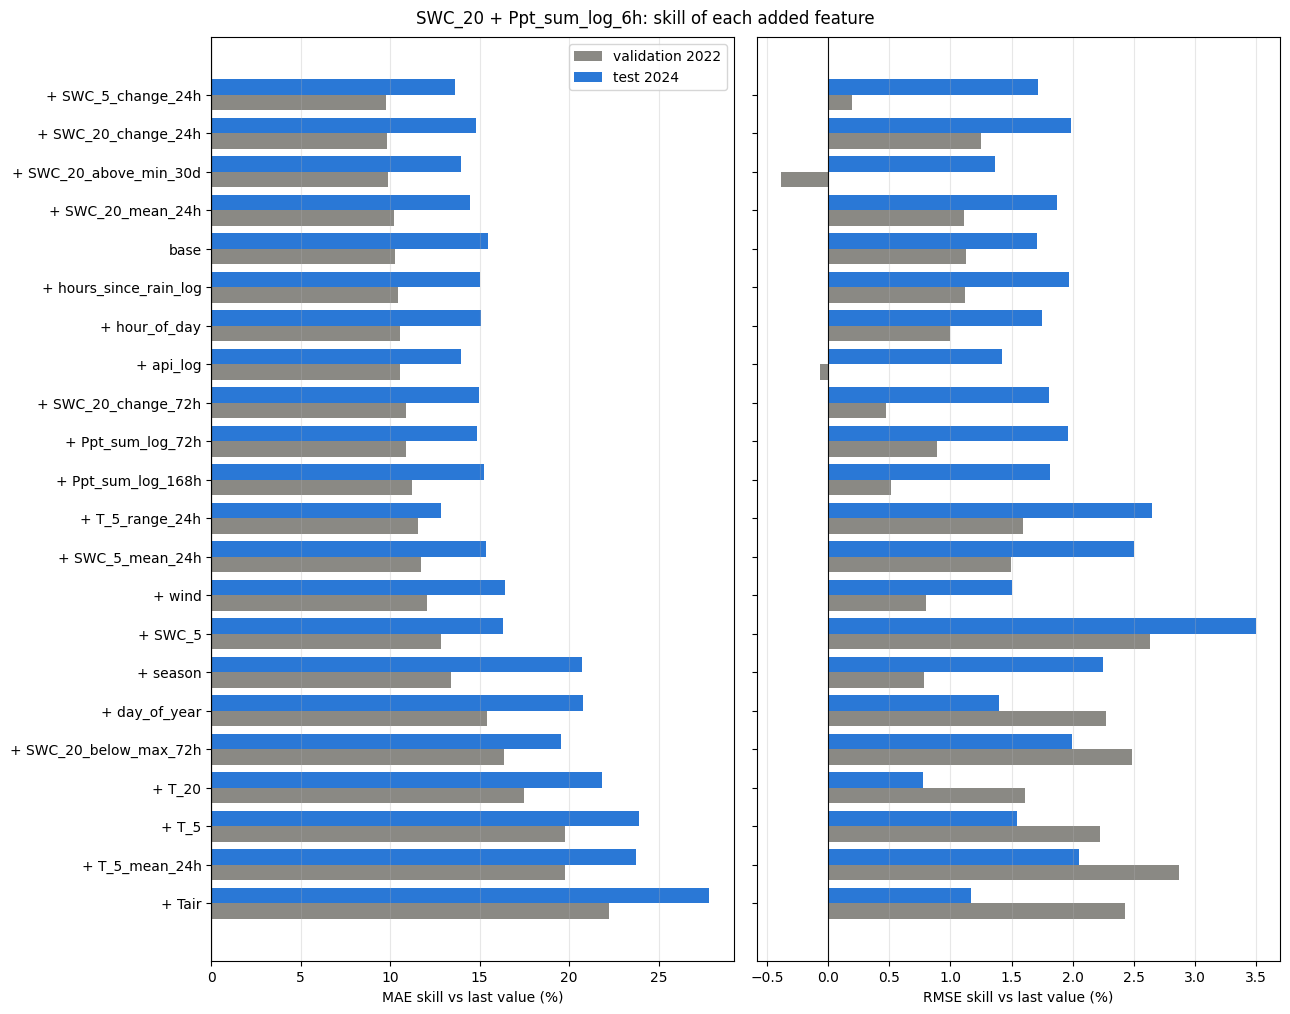

In [5]:
table = pd.DataFrame.from_dict(results, orient="index").sort_values("val_MAE_skill", ascending=False)
table.index.name = f"SWC_20 + Ppt_sum_log_{RAIN_HOURS}h"
table.to_csv(os.path.join(OUTPUT_DIR, f"results_ppt{RAIN_HOURS}h.csv"))
skill_cols = ["val_RMSE_skill", "val_MAE_skill", "test_RMSE_skill", "test_MAE_skill"]
display(table[skill_cols + ["test_RMSE", "test_MAE", "test_Bias", "best_epoch", "epochs_run"]].style
        .format("{:+.1%}", subset=skill_cols).format("{:.5f}", subset=["test_RMSE", "test_MAE"])
        .format("{:+.5f}", subset=["test_Bias"]))

test_w = make_windows("test", BASE_FEATURES)   # same targets for every feature set
pd.DataFrame({"actual": test_w["y_true"], "last_value": test_w["last"], **test_preds},
             index=test_w["target_time"]).to_csv(os.path.join(OUTPUT_DIR, f"test_predictions_ppt{RAIN_HOURS}h.csv"))

fig, axes = plt.subplots(1, 2, figsize=(13, 0.4 * len(table) + 1.5), sharey=True)
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    y = np.arange(len(table))
    ax.barh(y - 0.2, table[f"val_{metric}_skill"] * 100, height=0.4, color="#8a8984", label="validation 2022")
    ax.barh(y + 0.2, table[f"test_{metric}_skill"] * 100, height=0.4, color=C_BEST, label="test 2024")
    ax.axvline(0, color=C_ACTUAL, linewidth=0.8)
    ax.set_yticks(y, table.index)
    ax.invert_yaxis()
    ax.set_xlabel(f"{metric} skill vs last value (%)")
    ax.grid(axis="x", alpha=0.3)
axes[0].legend()
fig.suptitle(f"SWC_20 + Ppt_sum_log_{RAIN_HOURS}h: skill of each added feature")
plt.tight_layout()
plt.show()

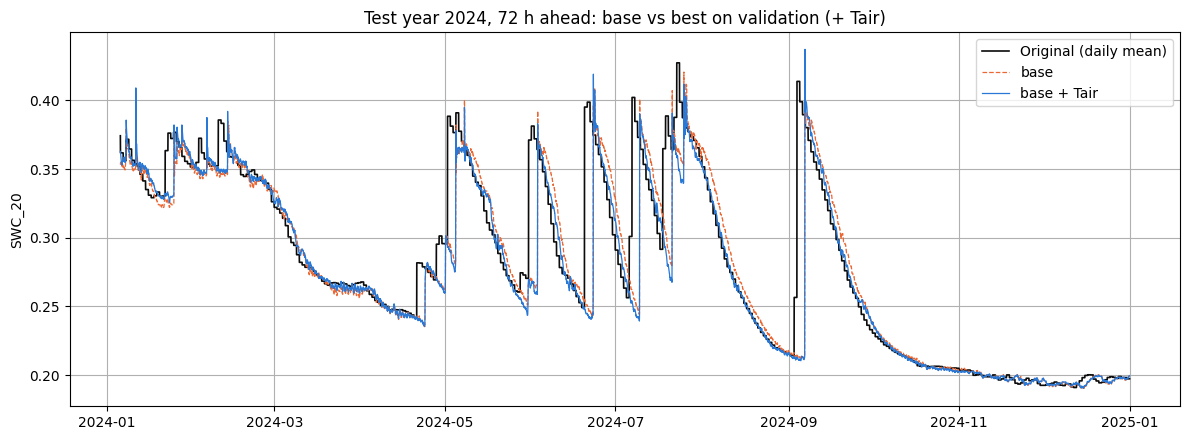

In [6]:
best = table.index[0]                                   # highest validation MAE skill
t = pd.DataFrame({"actual": test_w["y_true"], "base": test_preds["base"], "best": test_preds[best]},
                 index=test_w["target_time"])
plt.figure(figsize=(12, 4.5))
plt.plot(t.index, t["actual"], color=C_ACTUAL, linewidth=1.2, label="Original (daily mean)")
plt.plot(t.index, t["base"], color=C_BASE, linewidth=0.9, linestyle="--", label="base")
if best != "base":
    plt.plot(t.index, t["best"], color=C_BEST, linewidth=0.9, label=f"base {best}")
plt.title(f"Test year 2024, {HORIZON} h ahead: base vs best on validation ({best})")
plt.ylabel("SWC_20")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()